<a href="https://colab.research.google.com/github/bavucadoz/244107020162_ML_2026/blob/main/Minggu06/TG6_2441020162_AryaBayuSamodra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas**

*Jalankan code berikut pada Google Colab dan PyDroid3 (Android Python) Application di Smartphone Android. Bandingkan hasilnya dan tuliskan analisa anda, tuliskan juga spesifikasi smartphone yang anda gunakan :).*


---



In [1]:
!pip install annoy
!pip install faiss-cpu
!pip install hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 15.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520036 sha256=27cede0040df017ab5ff2f17ec445acc6f91a27efc703c1258e4d4aab1acbb08
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 61.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679799 sha256=e5594f25b40acba1d647252b2de8dc9ad2897937914ea323ff073976f40436c5
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib


In [3]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")

Exact NN done in 1.349 s
Annoy done in 0.637 s
HNSW done in 7.038 s
FAISS IVF done in 0.803 s

=== Ringkasan Waktu (detik) ===
Exact NN : 1.349
Annoy    : 0.637
HNSW     : 7.038
FAISS    : 0.803




---

**Hasil PyDroid3 (Android Python) Application di Smartphone Android**
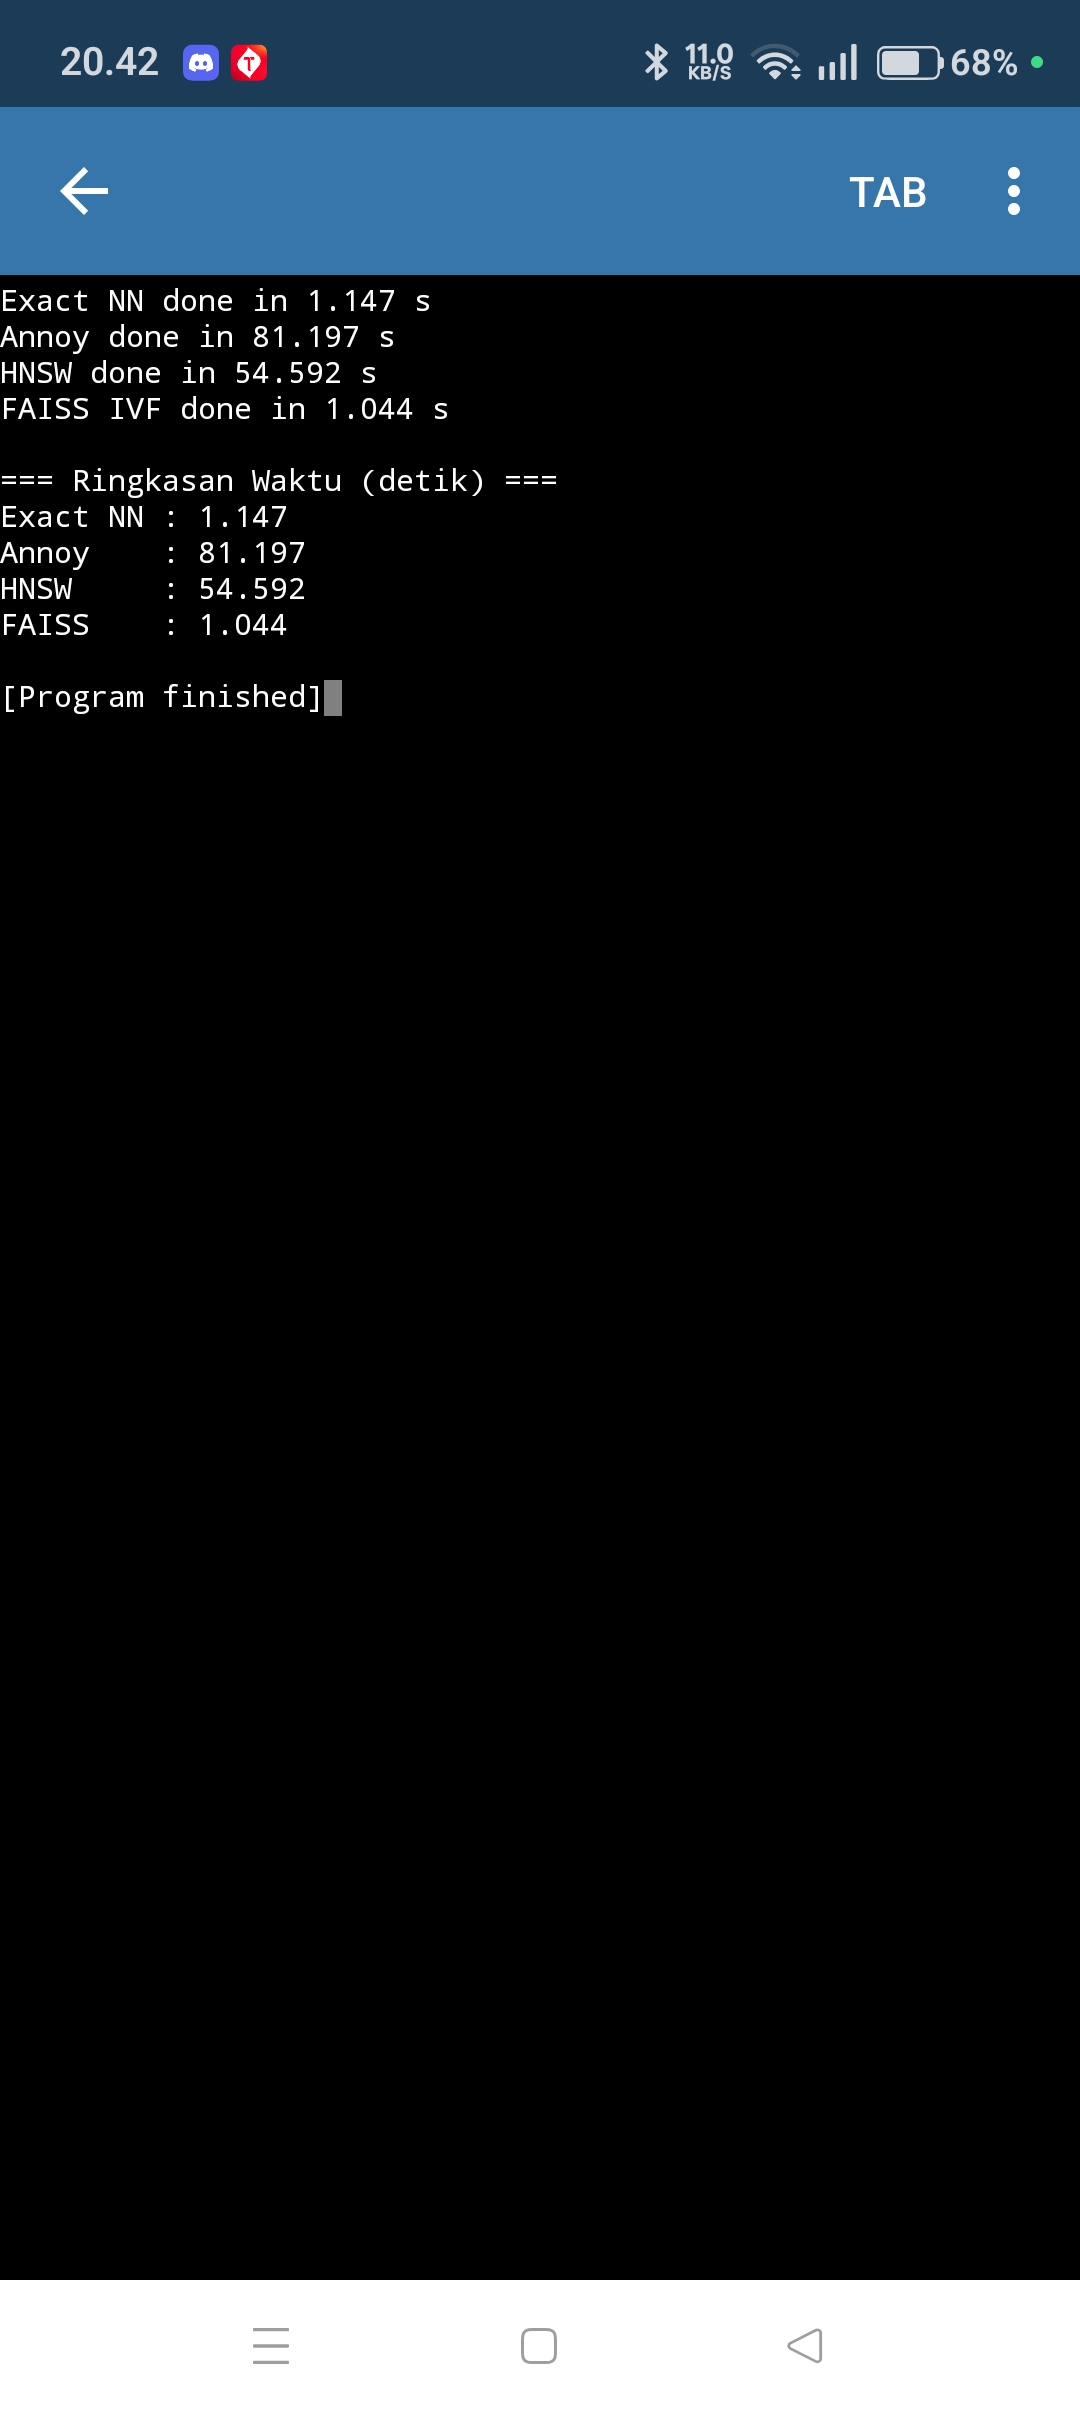



---

**Spekisifasi Handphone:**


*   Merk: Oppo Reno 11F 5G
*   Chipset: MediaTek Dimensity 7050 (6 nm)
*   CPU: Octa-core (2x2.6 GHz Cortex-A78 & 6x2.0 GHz Cortex-A55)
*   RAM: 8 GB




---


**Hasil Analisis:**

*   Hasil pengujian Exact NN dan FAISS memperlihatkan waktu eksekusi yang relatif seimbang antara Google Colab dan PyDroid3. Hal ini disebabkan oleh penggunaan fungsi scikit-learn dan NumPy yang sudah teroptimasi dengan vektorisasi matriks pada pustaka dasar C/BLAS di kedua lingkungan.
*   Terjadi lonjakan waktu yang sangat besar pada Annoy (81.197 detik) dan HNSW (54.592 detik) di PyDroid3. Hal ini terjadi karena di PyDroid3 eksekusi dilakukan menggunakan class simulator (wrapper) yang menjalankan perulangan loop 10.000 iterasi secara sekuensial di dalam interpreter Python. Sementara itu, Google Colab mengeksekusi biner native C++ asli dari pustaka Annoy dan HNSWlib secara langsung.

